# Imports

In [54]:
import numpy as np
import random
from scipy import stats
from collections import defaultdict
import matplotlib.pyplot as plt

# Constants

In [55]:
NUM_AGENTS = 10
NUM_ACTIONS = 5
HORIZON = 100
N_TRIALS = 100
MAX_REWARD_ABS_VAL = 10.0

# Policies

In [56]:
class EpsilonGreedy:
    def __init__(self, epsilon, num_actions, name="Epsilon Greedy"):
        self.name = name
        self.epsilon = epsilon
        self.q = {a: 0.0 for a in range(num_actions)}
        self.n = {a: 0 for a in range(num_actions)}

    def update(self, a, r):
        self.n[a] += 1
        self.q[a] += (r - self.q[a]) / self.n[a]

    def select(self, active_actions):
        if self.rng.random() < self.epsilon:
            return int(self.rng.choice(active_actions))

        best_value = max(self.q[a] for a in active_actions)
        best = [a for a in active_actions if self.q[a] == best_value]
        return int(self.rng.choice(best))


class Boltzmann:
    def __init__(self, temperature, num_actions, name="Boltzmann"):
        self.name = name
        self.temperature = temperature
        self.q = {a: 0.0 for a in range(num_actions)}
        self.n = {a: 0 for a in range(num_actions)}

    def update(self, a, r):
        self.n[a] += 1
        self.q[a] += (r - self.q[a]) / self.n[a]

    def select(self, active_actions):
        q_values = np.array([self.q[a] for a in active_actions])
        logits = (q_values - np.max(q_values)) / self.temperature

        exp_q = np.exp(logits)
        probabilities = exp_q / np.sum(exp_q)

        return int(self.rng.choice(active_actions, p=probabilities))


class UCB:
    def __init__(self, c, num_actions, name="UCB"):
        self.name = name
        self.c = c
        self.q = {a: 0.0 for a in range(num_actions)}
        self.n = {a: 0 for a in range(num_actions)}
        self.t = 0

    def update(self, a, r):
        self.n[a] += 1
        self.q[a] += (r - self.q[a]) / self.n[a]

    def select(self, active_actions):
        self.t += 1
        unvisited = [a for a in active_actions if self.n[a] == 0]

        if unvisited:
            return int(self.rng.choice(unvisited))

        ucb_values = {
            a: self.q[a] + self.c * np.sqrt(np.log(self.t) / self.n[a])
            for a in active_actions
        }

        best_value = max(ucb_values.values())
        best = [a for a in active_actions if ucb_values[a] == best_value]
        return int(self.rng.choice(best))


class Thompson:
    def __init__(self, num_actions, name="Thompson Policy"):
        self.name = name
        self.q = {a: 0.0 for a in range(num_actions)}
        self.n = {a: 0 for a in range(num_actions)}
        self.m2 = {a: 0.0 for a in range(num_actions)}

    def update(self, a, r):
        n = self.n[a] + 1
        old_mean = self.q[a]
        new_mean = old_mean + (r - old_mean) / n

        self.m2[a] += (r - old_mean) * (r - new_mean)

        self.q[a] = new_mean
        self.n[a] = n

    def select(self, active_actions):
        samples = []

        for a in active_actions:
            if self.n[a] < 2:
                std = 1.0
            else:
                std = np.sqrt(self.m2[a] / (self.n[a] - 1) / self.n[a])
                std = max(std, 1e-6)

            samples.append(self.rng.normal(self.q[a], std))

        return int(active_actions[np.argmax(samples)])


class GradientBandit:
    def __init__(self, alpha, num_actions, name="Gradient Bandit"):
        self.name = name
        self.alpha = alpha

        self.h = {a: 0.0 for a in range(num_actions)}
        self.reward_sum = {a: 0.0 for a in range(num_actions)}
        self.reward_count = {a: 0 for a in range(num_actions)}

        self.avg_r = 0.0
        self.active_actions = []
        self.probabilities = {}

    def update(self, a, r, active_actions):
        self.reward_sum[a] += r
        self.reward_count[a] += 1

        total_sum = sum(self.reward_sum[x] for x in active_actions)
        total_count = sum(self.reward_count[x] for x in active_actions)

        self.avg_r = total_sum / total_count if total_count else 0.0

        for action in active_actions:
            if action == a:
                self.h[action] += (
                    self.alpha * (r - self.avg_r)
                    * (1 - self.probabilities[action])
                )
            else:
                self.h[action] -= (
                    self.alpha * (r - self.avg_r)
                    * self.probabilities[action]
                )

    def select(self, active_actions):
        self.active_actions = list(active_actions)

        logits = np.array([self.h[a] for a in active_actions])
        logits -= np.max(logits)

        exp_h = np.exp(logits)
        probs = exp_h / np.sum(exp_h)

        self.probabilities = dict(zip(active_actions, probs))

        return int(self.rng.choice(active_actions, p=probs))

# Environment

In [57]:
class Environment:
    def __init__(self, rng, num_actions):
        self.rng = rng
        self.r_max_i = rng.uniform(0, 10, num_actions)
        self.r_min_i = rng.uniform(-10, 0, num_actions)
        self.p_i = rng.uniform(0.2, 0.8, num_actions)
        self.z_i = rng.integers(80, 151, num_actions)
        self.active = np.ones(num_actions, dtype=bool)

    def step(self, action):
        success = self.rng.random() < self.p_i[action]
        reward = self.r_max_i[action] if success else self.r_min_i[action]
        if reward > 0:
            self.z_i[action] -= 1
            if self.z_i[action] <= 0:
                self.active[action] = False
        return reward

# Agent

In [58]:
class Agent:
    def __init__(self, num_actions, policy, rng):
        self.num_actions = num_actions
        self.policy = policy
        self.policy.rng = rng

    def select(self, active):
        return self.policy.select(active)

    def update(self, a, r, active):
        if isinstance(self.policy, GradientBandit):
            self.policy.update(a, r, active)
        else:
            self.policy.update(a, r)

# Experiment

In [59]:
def run_trial(num_actions, policies, L, seed):
    algo_names = list(dict.fromkeys(policy.name for policy in policies))
    algo_counts = {
        name: sum(1 for p in policies if p.name == name)
        for name in algo_names
    }

    ss = np.random.SeedSequence(seed)
    env_seed, order_seed, agent_seed, reward_seed = ss.spawn(4)
    env_rng = np.random.default_rng(env_seed)
    order_rng = np.random.default_rng(order_seed)
    agent_seeds = np.random.default_rng(agent_seed).spawn(len(policies))

    env = Environment(env_rng, num_actions)
    agents = [
        Agent(num_actions, policy, np.random.default_rng(agent_seeds[i]))
        for i, policy in enumerate(policies)
    ]

    r_round = np.zeros(L)
    cum_population = np.zeros(L)
    cum_agent = np.zeros((len(agents), L))
    cum_algo = {name: np.zeros(L) for name in algo_names}
    n_active = np.zeros(L)

    running_person = np.zeros(len(agents))
    running_algo = {name: 0.0 for name in algo_names}

    for t in range(L):
        order = order_rng.permutation(len(agents))
        rewards = np.zeros(len(agents))

        for idx in order:
            agent = agents[idx]
            active_actions = np.where(env.active)[0]

            if len(active_actions) == 0:
                break

            action = agent.select(active_actions)
            reward = env.step(action)
            agent.update(action, reward, active_actions)

            rewards[idx] = reward
            running_person[idx] += reward
            running_algo[policies[idx].name] += reward

        r_round[t] = rewards.mean()
        cum_agent[:, t] = running_person

        for name in algo_names:
            cum_algo[name][t] = running_algo[name] / algo_counts[name]

        cum_population[t] = running_person.sum()
        n_active[t] = np.sum(env.active)

    return {
        "r_round": r_round,
        "cum_population": cum_population,
        "cum_agent": cum_agent,
        "cum_algo": cum_algo,
        "n_active": n_active,
    }

In [60]:
def mean_ci(arr_2d, confidence=0.95):
    n_trials = arr_2d.shape[0]
    m = arr_2d.mean(axis=0)
    se = arr_2d.std(axis=0, ddof=1) / np.sqrt(n_trials)
    h = se * stats.t.ppf((1 + confidence) / 2, n_trials - 1)
    return m, h

def plot_mean_ci(x, mean, half_width, label=None, ax=None, alpha=0.2):
    ax = ax or plt.gca()
    ax.plot(x, mean, label=label)
    ax.fill_between(x, mean - half_width, mean + half_width, alpha=alpha)

# Finding Hyperparameters

In [61]:
reward = {}
for eps in np.linspace(0.01, 1.0, 100):
    policy = (EpsilonGreedy(epsilon=eps, num_actions=NUM_ACTIONS),)
    results = [run_trial(NUM_ACTIONS, policy, HORIZON, seed+N_TRIALS) for seed in range(5)]

    cum_agent = np.stack([r["cum_agent"][-1] for r in results])
    reward[eps] = np.mean(cum_agent)
eps = float(max(reward, key=reward.get))
eps

0.43

In [62]:
reward = {}
for tau in np.linspace(0.01, 3.0, 100):
    policy = (Boltzmann(temperature=tau, num_actions=NUM_ACTIONS),)
    results = [run_trial(NUM_ACTIONS, policy, HORIZON, seed+N_TRIALS) for seed in range(5)]

    cum_agent = np.stack([r["cum_agent"][-1] for r in results])
    reward[tau] = np.mean(cum_agent)
tau = float(max(reward, key=reward.get))
tau

0.3120202020202021

In [63]:
reward = {}
for alpha in np.linspace(0.01, 1.0, 100):
    policy = (GradientBandit(alpha=alpha, num_actions=NUM_ACTIONS),)
    results = [run_trial(NUM_ACTIONS, policy, HORIZON, seed+N_TRIALS) for seed in range(5)]

    cum_agent = np.stack([r["cum_agent"][-1] for r in results])
    reward[alpha] = np.mean(cum_agent)
alpha = float(max(reward, key=reward.get))
alpha

0.18000000000000002

# A) Heterogeneous Population

In [64]:
def run_trials(policy_factories,n_trials,horizon,num_actions):
    results = []
    for seed in range(n_trials):
        results.append(run_trial(num_actions, [f() for f in policy_factories], horizon, seed))

    algo_names = list(results[0]["cum_algo"].keys())

    r_round = np.stack([r["r_round"] for r in results])
    n_active = np.stack([r["n_active"] for r in results])
    cum_population = np.stack([r["cum_population"] for r in results])
    cum_agent = np.stack([r["cum_agent"] for r in results])
    cum_algo = {
        name: np.stack([r["cum_algo"][name] for r in results])
        for name in algo_names
    }
    return r_round, n_active, cum_population, cum_agent, cum_algo

In [65]:
def report_results(policies, num_actions, r_round, n_active, cum_population, cum_algo):
    rounds = np.arange(1, HORIZON + 1)
    for i, (metric, title) in enumerate(zip([r_round, n_active, cum_population], 
    ["Average Reward", "Number of Active Actions", "Cumulative Reward of Population"])):
        m, h = mean_ci(metric)

        fig, ax = plt.subplots(figsize=(8, 5))
        plot_mean_ci(rounds, m, h, ax=ax)
        ax.set_xlabel("Round")
        ax.set_ylabel(title)
        ax.set_title(title + " per Round")
        if i == 1:
            ax.set_ylim([0, num_actions*1.1])
        ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

    algo_names = list(cum_algo.keys())
    fig, ax = plt.subplots(figsize=(9, 6))
    for name in algo_names:
        m, h = mean_ci(cum_algo[name])
        plot_mean_ci(rounds, m, h, label=name, ax=ax, alpha=0.1)

    ax.set_xlabel("Round")
    ax.set_ylabel("Cumulative Reward per Agent")
    ax.set_title("Average Cumulative Reward per Algorithm (95% CI)")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

In [66]:
def run_and_report(policies,n_trials=N_TRIALS,horizon=HORIZON,num_actions=NUM_ACTIONS):
    r_round, n_active, cum_population, cum_agent, cum_algo = run_trials(policies,n_trials,horizon,num_actions)
    report_results(policies, num_actions, r_round, n_active, cum_population, cum_algo)

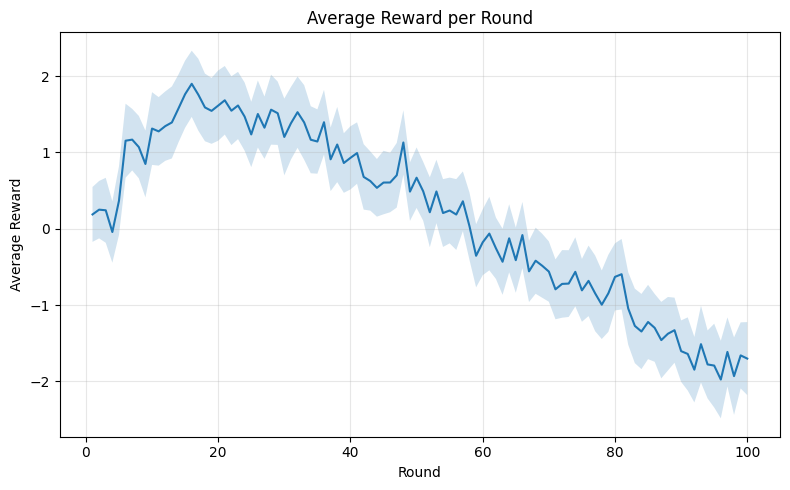

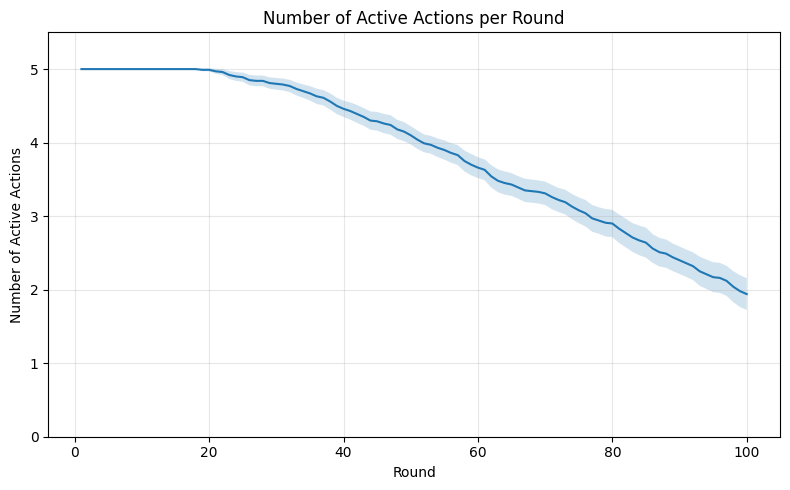

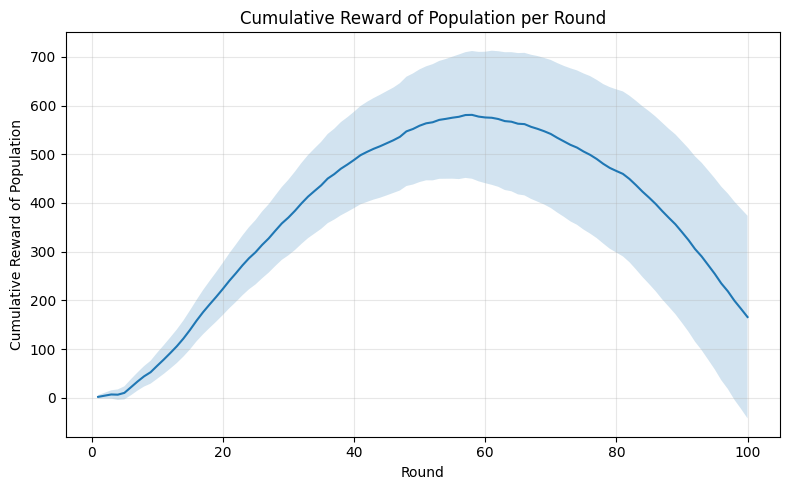

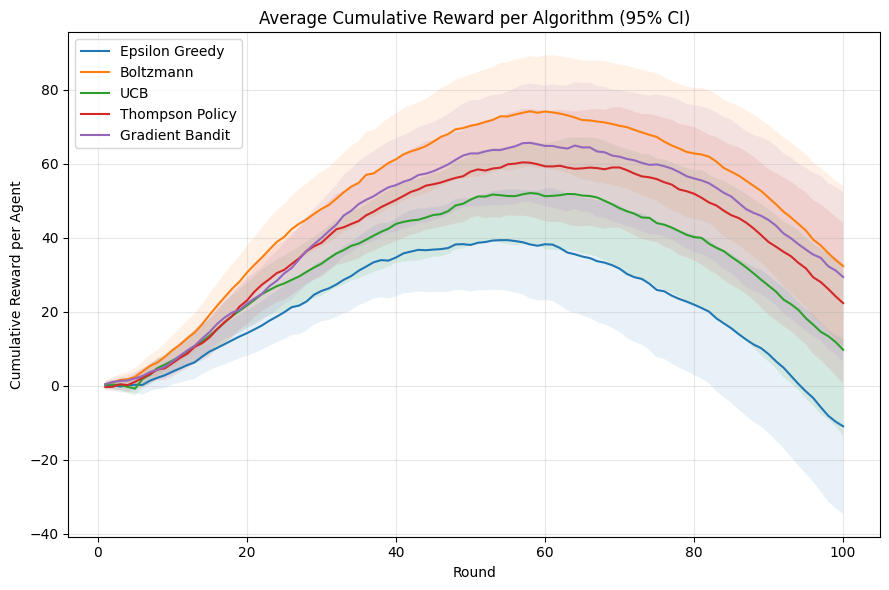

In [67]:
policies = []
for _ in range(2):
    policies.append(lambda: EpsilonGreedy(epsilon=eps, num_actions=NUM_ACTIONS))
    policies.append(lambda: Boltzmann(temperature=tau, num_actions=NUM_ACTIONS))
    policies.append(lambda: UCB(c=MAX_REWARD_ABS_VAL, num_actions=NUM_ACTIONS))
    policies.append(lambda: Thompson(num_actions=NUM_ACTIONS))
    policies.append(lambda: GradientBandit(alpha=alpha, num_actions=NUM_ACTIONS))

r_round, n_active, cum_population, cum_agent, cum_algo = run_trials(policies,N_TRIALS,HORIZON,NUM_ACTIONS)
report_results(policies, NUM_ACTIONS, r_round, n_active, cum_population, cum_algo)

* How does the reward of the population change and what is the reason?

The average reward keeps increasing until about the 15th round. After that it starts decreasing going negative from round 60. Consequently, the cumulative reward of the population starts decreasing from the 60th round until the end.

The reason may be due to the limited amount of resources, after the valuable resources with great $p_i$ and $r_{max,i}$ finish the agents will be forced to select less valuable resources and after some point only the resources with $p_i < 0.5$ will remain which cause an overall negative reward.

* How do disabled actions affect the algorithms' behavior?

As expected, the number of enabled actions keeps decreasing with the first action becoming disabled some wher around the 20th to 55th round. As the number of available actions decreases, the models are forced to select less valuable actions and get less reward. So the best algorithm here not only should detect the optimal action but also it should detect the next optimal actions to be able to be successful overall.

* Does a successful algorithm have a positive impact on the population?

Not necessarily, for example a successful algorithm may always detect the best ation and select it but the other algorithms may only be able to detect the optimal action once. The successful algorithm would cause the optimal resource to finish faster thus from that point on, the other actions would hurt the society. Thus each action's self successful performance doesn't necessarily have an overall positive impact on the society.

* Why would we need to modify the current Bandit algorithms for this problem?

There are several reasons for this including the fact that the number of active actions change after some time, thus the environment is not static which is assumed to be true for these algorithms. Also by designing algorithms that are aware of the existence of the other agents, we may be able to increase the society's overall benefit.

* How can the hyperparameters of the algorithms affect the results?

These hyperparameters determine the amount of risk the agent would be willing to take and the balance between eploration and eplotation. For example by exploring more, the agent may get behind the other algorithms for a while but it could correctly rank the actions thus it may perform better after the optimal action gets disabled, on the other hand exploiting earlier could benefit the agent which is in compete with the others for the optimal action.

I

# Homogeneous Popoulation

## Eps-Greedy

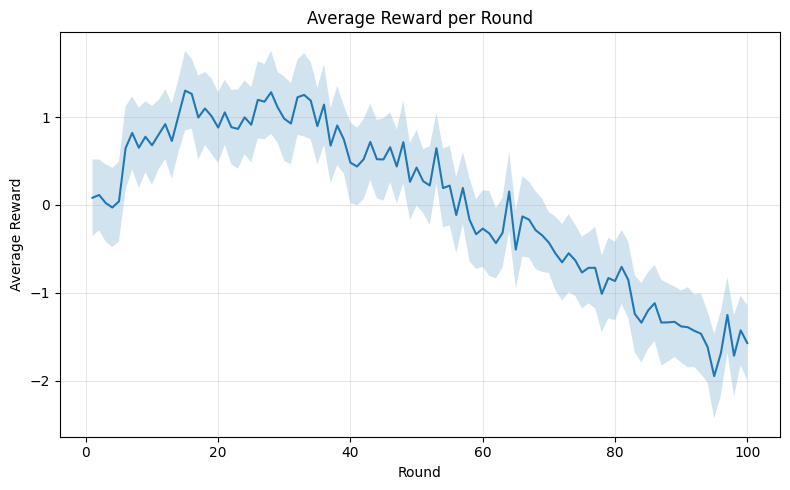

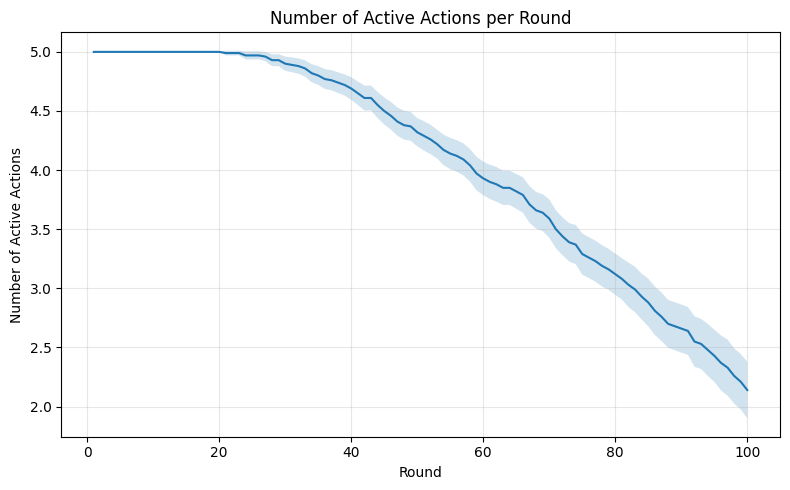

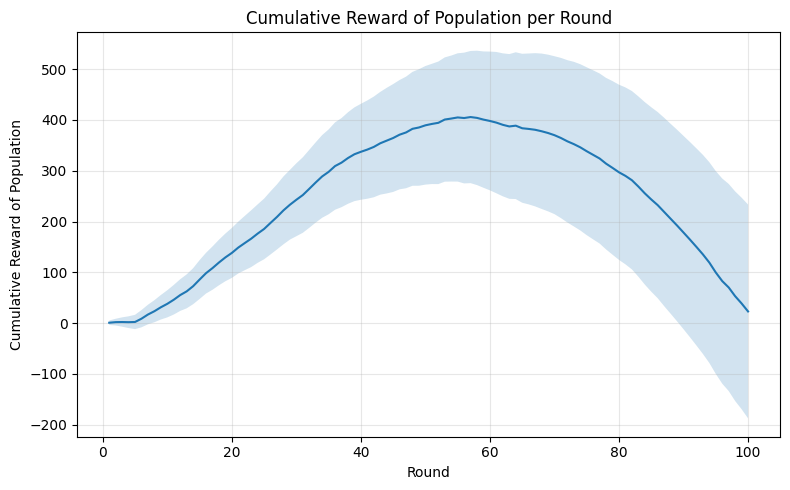

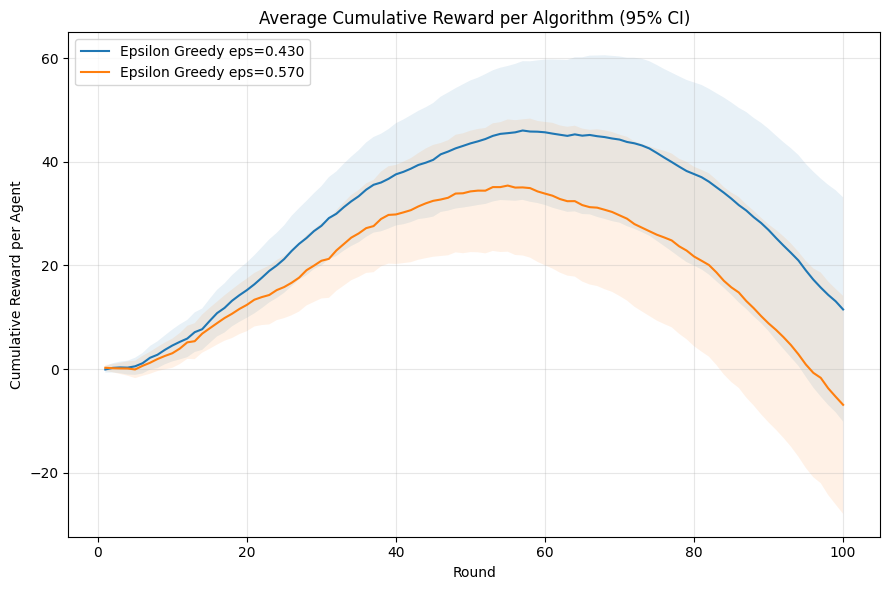

In [ ]:
policies = []
eps2 = 1-eps
for _ in range(5):
    policies.append(lambda: EpsilonGreedy(epsilon=eps, num_actions=NUM_ACTIONS, name=f"Epsilon Greedy eps={eps:.3f}"))
    policies.append(lambda: EpsilonGreedy(epsilon=eps2, num_actions=NUM_ACTIONS, name=f"Epsilon Greedy eps={eps2:.3f}"))

run_and_report(policies)

## UCB

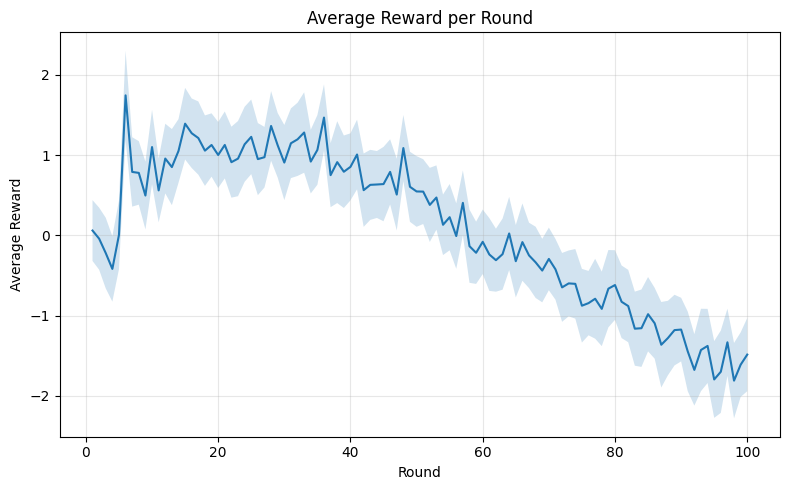

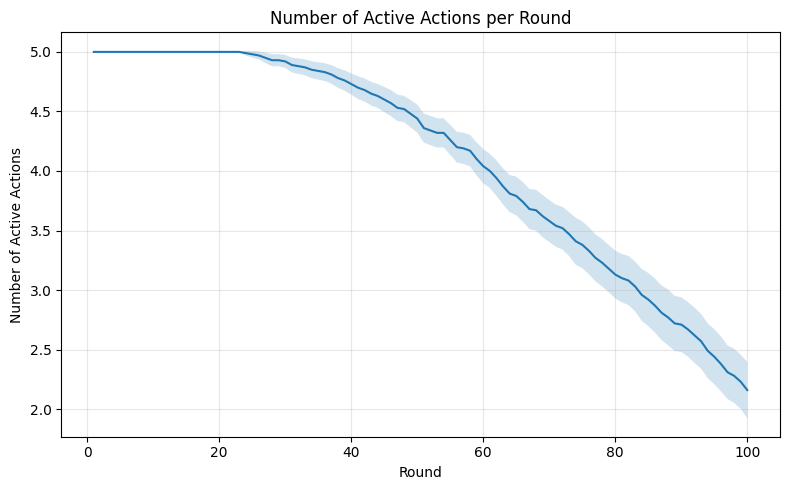

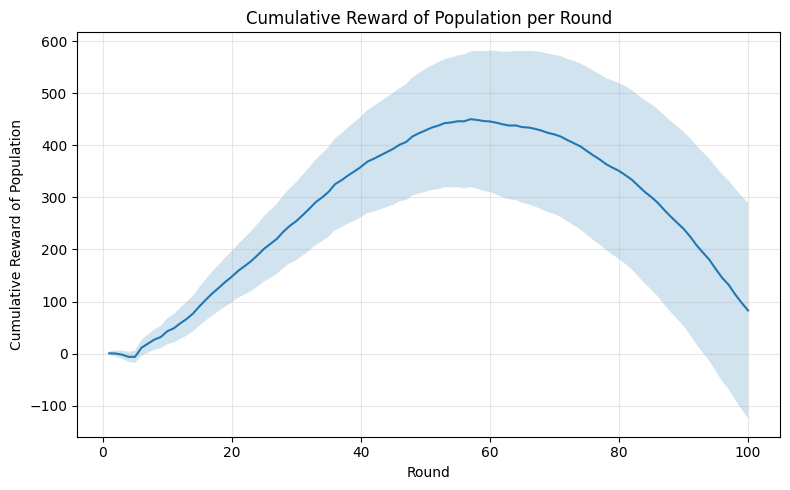

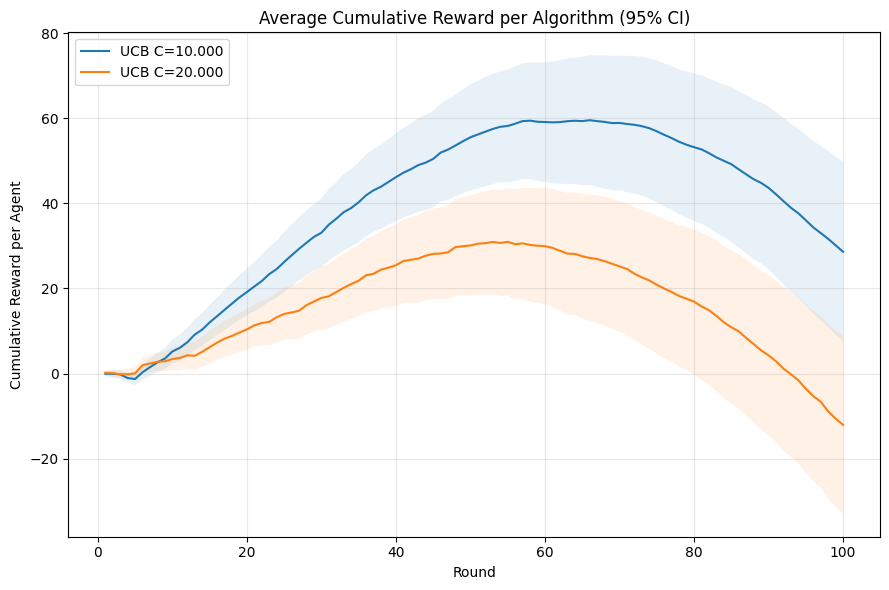

In [ ]:
policies = []
c2 = 2*MAX_REWARD_ABS_VAL
for _ in range(5):
    policies.append(lambda: UCB(c=MAX_REWARD_ABS_VAL, num_actions=NUM_ACTIONS, name=f"UCB C={MAX_REWARD_ABS_VAL:.3f}"))
    policies.append(lambda: UCB(c=c2, num_actions=NUM_ACTIONS, name=f"UCB C={c2:.3f}"))

run_and_report(policies)

## Gradient Bandit

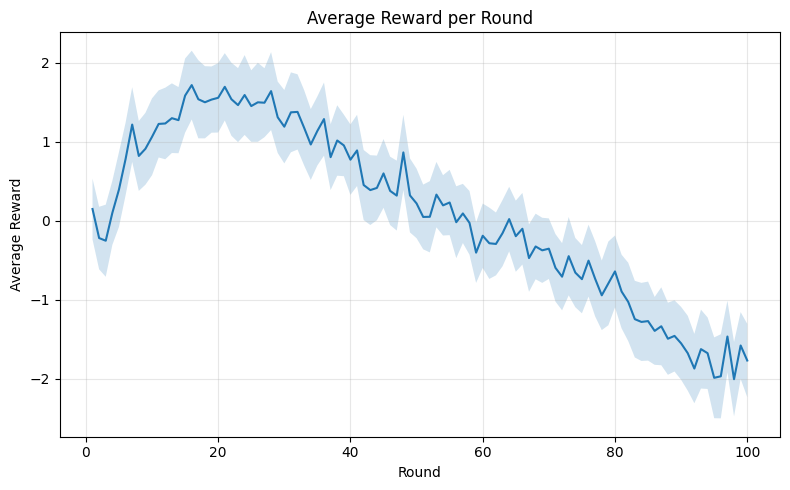

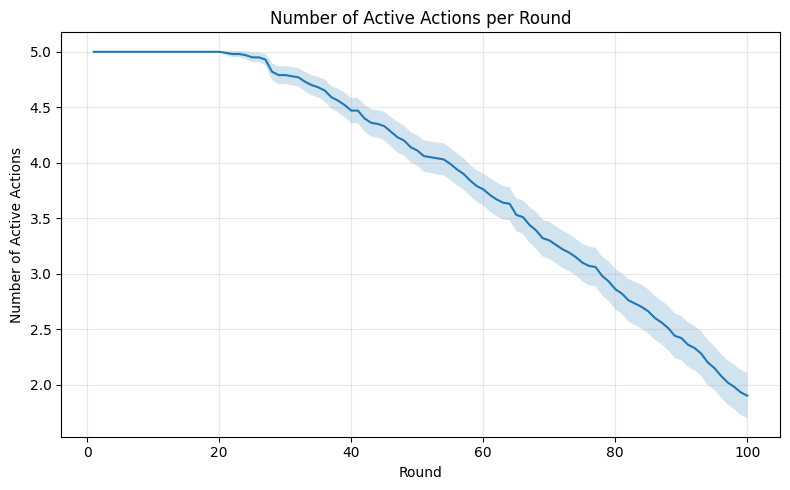

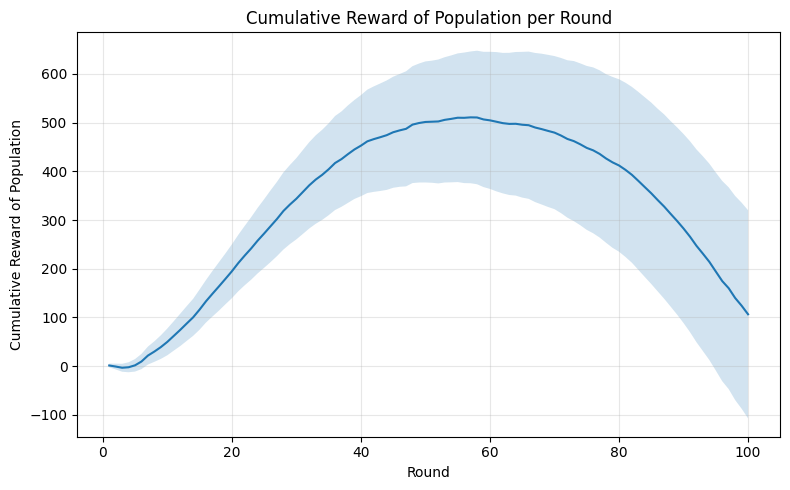

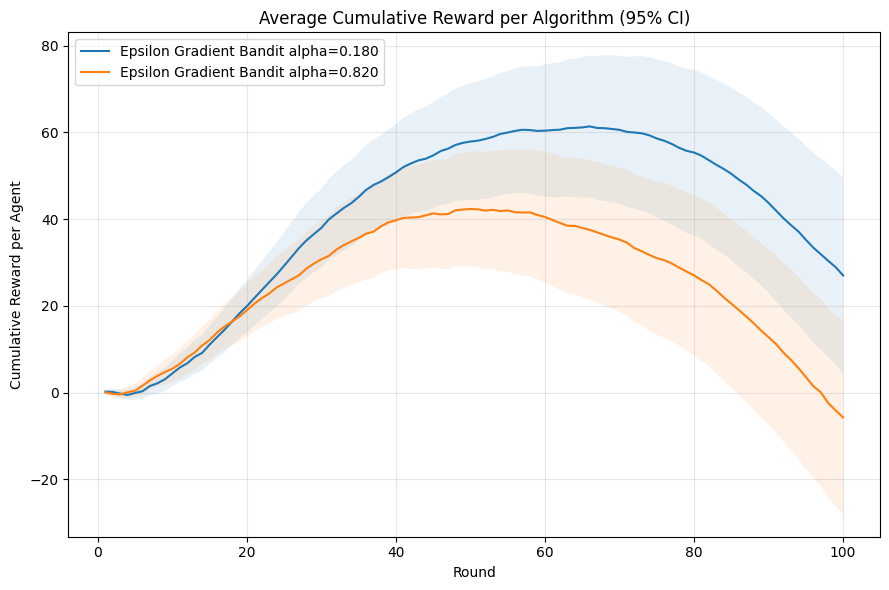

In [ ]:
policies = []
alpha2 = 1-alpha
for _ in range(5):
    policies.append(lambda: GradientBandit(alpha=alpha, num_actions=NUM_ACTIONS, name=f"Epsilon Gradient Bandit alpha={alpha:.3f}"))
    policies.append(lambda: GradientBandit(alpha=alpha2, num_actions=NUM_ACTIONS, name=f"Epsilon Gradient Bandit alpha={alpha2:.3f}"))

run_and_report(policies)

# Measure sensitivity